# steerbench walkthrough

**Which trajectory-correction strategy reaches target quality in the fewest interactions with the machine, when the optics model is imperfect, BPMs are missing and the machine drifts?**

## 1. Problem and motivation

Steering the beam along a transfer line is routine accelerator operation: correctors kick the beam and beam-position monitors (BPMs) read where it goes. Operators classically invert a model of the orbit response (SVD correction). Reinforcement learning has been demonstrated for the same task at CERN with remarkably few machine interactions (V. Kain et al., *Phys. Rev. Accel. Beams* **23**, 124801, 2020), and automating such routine tuning is a central aim of making accelerators run themselves (V. Kain, "Accelerators on autopilot", *CERN Courier*, May 2025).

On a real machine every interaction costs beam time, so this benchmark counts **deployment interactions** on the target machine and reports simulation training cost separately. This notebook only reads cached results from `results/` and retrains nothing; every number shown is computed from those files.

In [1]:
%matplotlib inline
import os
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display

from steerbench import plotting, report
from steerbench.config import load_config
from steerbench.controllers.rl import RLController, load_agent
from steerbench.evaluation import trajectory_snapshots
from steerbench.experiments import CLASSICAL, controller_rng, load_hyperparams, rl_agent_path
from steerbench.machine import make_machines
from steerbench.optics import build_fodo, propagate_twiss, response_matrix

os.chdir(report.repo_root())  # result paths in the config are relative to the repository
cfg = load_config("configs/full.yaml")
RES, BUDGET = Path(cfg.results_dir), cfg.eval.max_interactions
results = report.Results.load(RES, BUDGET)
hps = load_hyperparams(cfg)
display(Markdown(report.setup_block(cfg)))

- **Line:** thin-lens FODO, 10 cells, 5 m between quadrupoles, 90 deg phase advance per cell; 20 BPMs (one per quadrupole), 10 correctors (one per focusing quadrupole).
- **Errors per machine:** focal-length errors (nominal sigma 3%), BPM gains (1%), corrector gains (1%), quadrupole offsets (100 um), injection offset/angle (500 um / 50 urad); BPM noise 50 um.
- **Limits:** |theta| <= 200 urad, |dtheta| <= 200 urad per interaction.
- **Protocol:** 50 held-out test machines, 20 separate validation machines for tuning, 30 interactions per episode, success when the normalised excess RMS drops below 0.05; 5 training seeds per learned method; 6 tuning trials per method; 1000 bootstrap resamples over machines for 95% CIs.
- **Sweeps:** focal error 0%, 1%, 3%, 5%, 10% (E2) and 15%, 20%, 30% (E2X extension); unavailable BPMs 0%, 10%, 25%, 40% (E3); 200 drifting episodes on 5 machines (E4); offline datasets 10k, 50k x behaviour noise 5 urad, 20 urad, 50 urad (E5).
- **Online RL:** SAC and TD3 (stable-baselines3), 100,000 steps per agent on machines with focal-error level drawn from 0-10% and 0-40% of BPMs unavailable.

## 2. Lattice and response matrix

A periodic thin-lens FODO line. The matched beta function alternates between its maximum at the focusing quadrupoles (where the correctors sit) and its minimum at the defocusing ones; the phase advances by the design amount per cell. The response matrix is lower-triangular in structure (a corrector cannot move the beam upstream of itself), and at this phase advance every other entry along a column vanishes.

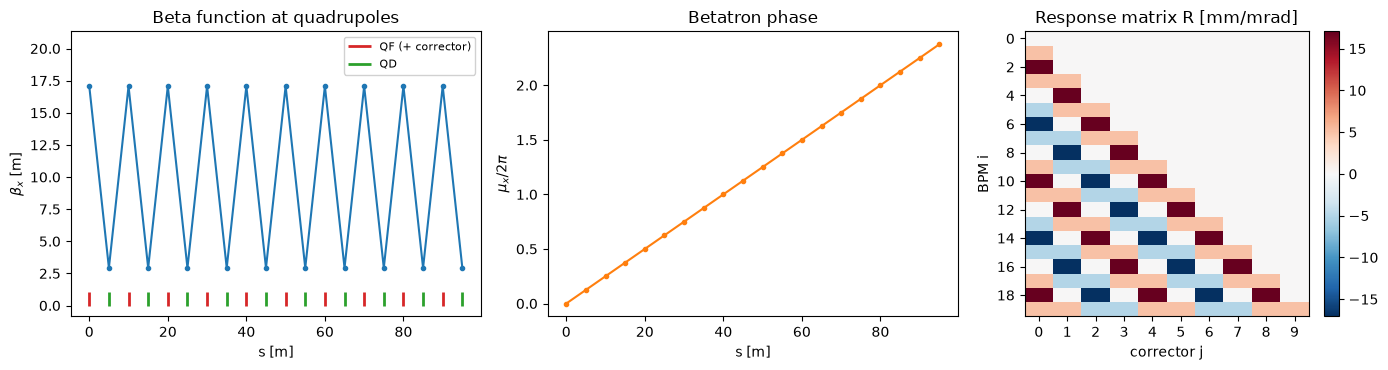

In [2]:
lattice = build_fodo(cfg.machine.lattice)
twiss = propagate_twiss(lattice)
R = response_matrix(lattice, twiss)
plotting.plot_lattice(lattice, twiss, R);

- The unconstrained oracle correction lies within the corrector limit for 97% at 0%, 97% at 1%, 97% at 3%, 96% at 5%, 96% at 10% focal error (1000 sampled machines per level).
- SVD with the exact model, no noise and gain 1 reaches the oracle residual in one interaction on 49 of 50 test machines (largest gap 6.6e-17 mm); on the remaining machine(s) the oracle needs kicks beyond the limit.

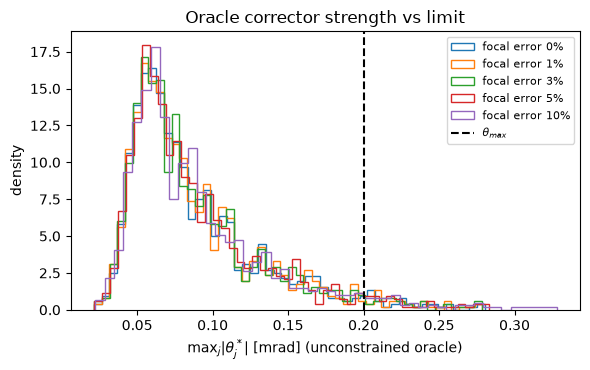

In [3]:
display(Markdown(report.e0_block(RES)))
samples = pd.read_csv(RES / "e0_oracle_samples.csv")
plotting.plot_oracle_kicks(samples, cfg.machine.limits.theta_max_mrad);

## 3. One episode visualised

The true trajectory on one held-out test machine at nominal conditions, before correction and after one environment horizon of interactions with SVD, RLS and SAC (all with their tuned hyperparameters; SAC is the first training seed). The dashed line is the best achievable trajectory, which the oracle finds with knowledge of the true optics.

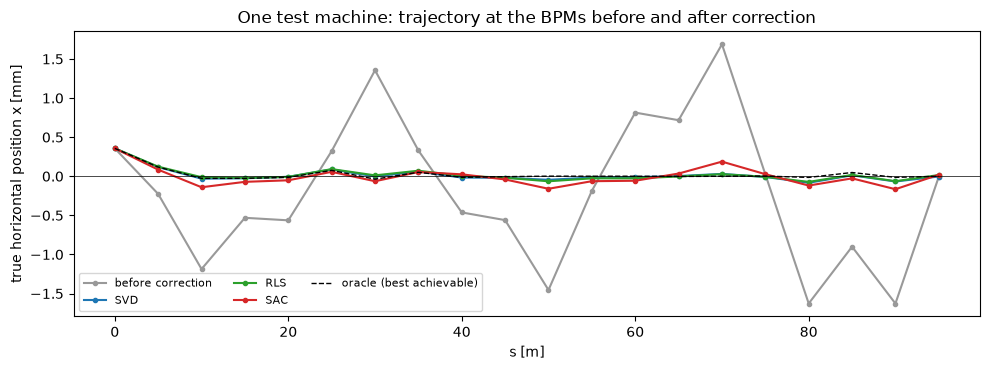

In [4]:
def fresh_machine():
    return make_machines(cfg.machine, 1, cfg.eval.test_seed)[0]


def snapshot(make_controller):
    m = fresh_machine()
    return trajectory_snapshots(m, make_controller(m), cfg.env.horizon)


sac = load_agent("SAC", rl_agent_path(cfg, "SAC", 0))
makers = {
    "SVD": lambda m: CLASSICAL["SVD"].factory(m.model_info, controller_rng(0), hps["SVD"]),
    "RLS": lambda m: CLASSICAL["RLS"].factory(m.model_info, controller_rng(0), hps["RLS"]),
    "SAC": lambda m: RLController(sac, m.model_info, cfg, "SAC", hps["SAC"]),
}
snaps = {name: snapshot(make) for name, make in makers.items()}
m0 = fresh_machine()
before = next(iter(snaps.values()))[0]
plotting.plot_trajectories(
    lattice.s, before, {k: v[1] for k, v in snaps.items()}, m0.true_trajectory(m0.oracle().theta)
);

## 4. Benchmark results

### E1: nominal conditions

Median (with interquartile band) normalised excess RMS against deployment interactions on the held-out test machines. The response-measurement method spends its first interactions kicking each corrector, which is why its curve rises before it drops.

| Method | Success rate [95% CI] | Interactions to success, median [IQR] | Final excess e, median | Simulation training cost |
|---|---|---|---|---|
| SVD | 100% [100%, 100%] | 2 [2, 3] | 0.007 | none |
| RLS | 100% [100%, 100%] | 2 [2, 2] | 0.008 | none |
| RM-SVD | 98% [94%, 100%] | 11 [11, 11] | 0.013 | none |
| BO | 0% [0%, 0%] | >30 [>30, >30] | 0.641 | none |
| BO-SVDmodes | 0% [0%, 0%] | >30 [>30, >30] | 0.261 | none |
| SAC | 60% [51%, 69%] | 18 [9, >30] | 0.070 | 100,000 env steps (+600,000 tuning) |
| TD3 | 49% [40%, 57%] | >30 [8, >30] | 0.088 | 100,000 env steps (+600,000 tuning) |
| Behaviour | 8% [2%, 16%] | >30 [>30, >30] | 0.503 | none |
| BC (10k) | 24% [17%, 33%] | >30 [>30, >30] | 0.202 | 10,000 logged transitions, 20,000 gradient steps |
| BC (50k) | 78% [69%, 85%] | 5 [4, 13] | 0.049 | 50,000 logged transitions, 20,000 gradient steps |
| TD3+BC (10k) | 16% [11%, 22%] | >30 [>30, >30] | 0.234 | 10,000 logged transitions, 20,000 gradient steps |
| TD3+BC (50k) | 28% [20%, 35%] | >30 [19, >30] | 0.155 | 50,000 logged transitions, 20,000 gradient steps |
| SVD (true R, reference) | 100% [100%, 100%] | 2 [2, 2] | 0.007 | none |

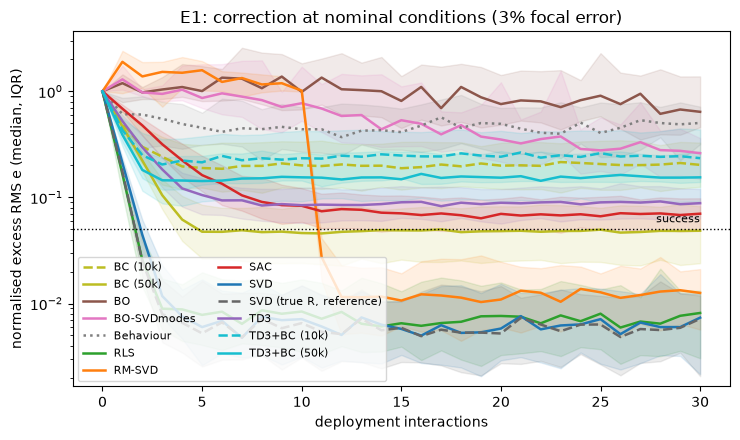

In [5]:
plotting.plot_excess_vs_interactions(pd.read_csv(RES / "e1_curves.csv"), cfg.eval.success_threshold)
display(Markdown(report.main_table(results)))

### E2 (and its extension E2X): model error

The headline result. The shaded region extends the specified sweep to find where classical correction stops winning; the RL agents never saw such large errors during training.

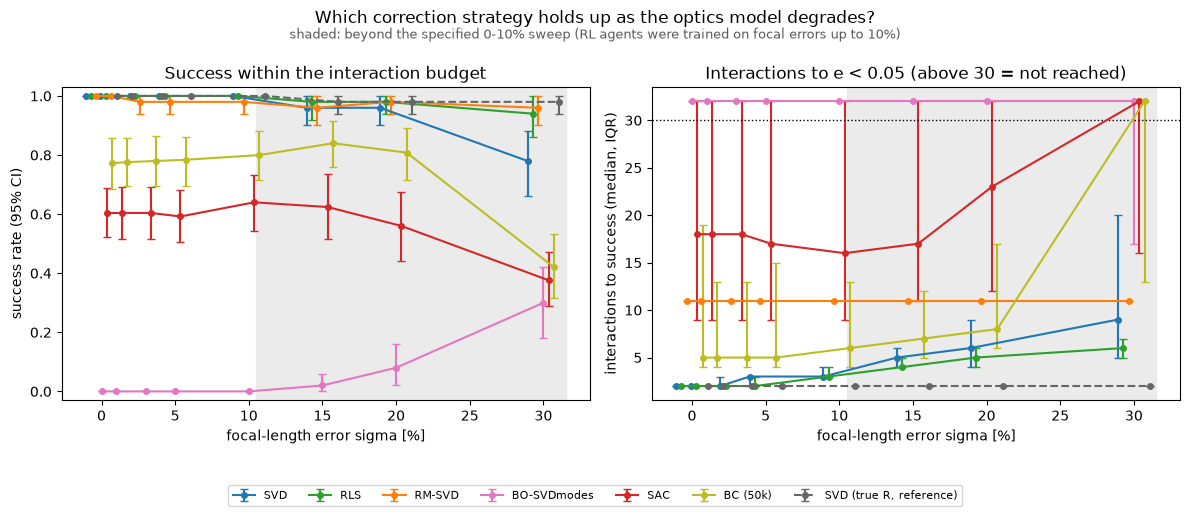

In [6]:
plotting.plot_headline(results.e2, BUDGET, report.HEADLINE_METHODS);

In [7]:
display(Markdown(report.robustness_table(results)))

| Method | focal 0% | focal 10% | focal 20%* | focal 30%* | BPMs off 25% | BPMs off 40% | drift, last quarter |
|---|---|---|---|---|---|---|---|
| SVD | 100% | 100% | 96% | 78% | 86% | 62% | 100% |
| RLS | 100% | 100% | 98% | 94% | 84% | 56% | 100% |
| RM-SVD | 100% | 98% | 98% | 96% | 72% | 28% | - |
| BO-SVDmodes | 0% | 0% | 8% | 30% | 0% | 0% | - |
| SAC | 60% | 64% | 56% | 38% | 7% | 3% | 39% |
| BC (50k) | 77% | 80% | 81% | 42% | 29% | 12% | - |
| SVD (true R, reference) | 100% | 100% | 98% | 98% | 86% | 62% | - |
| TD3 | 44% | 51% | 40% | 20% | 4% | 0% | - |
| TD3+BC (50k) | 26% | 32% | 34% | 18% | 8% | 4% | - |
| Behaviour | 8% | 8% | 12% | 32% | 8% | 8% | - |
| SAC (fine-tuned online) | - | - | - | - | - | - | 50% |

### E3: missing BPMs

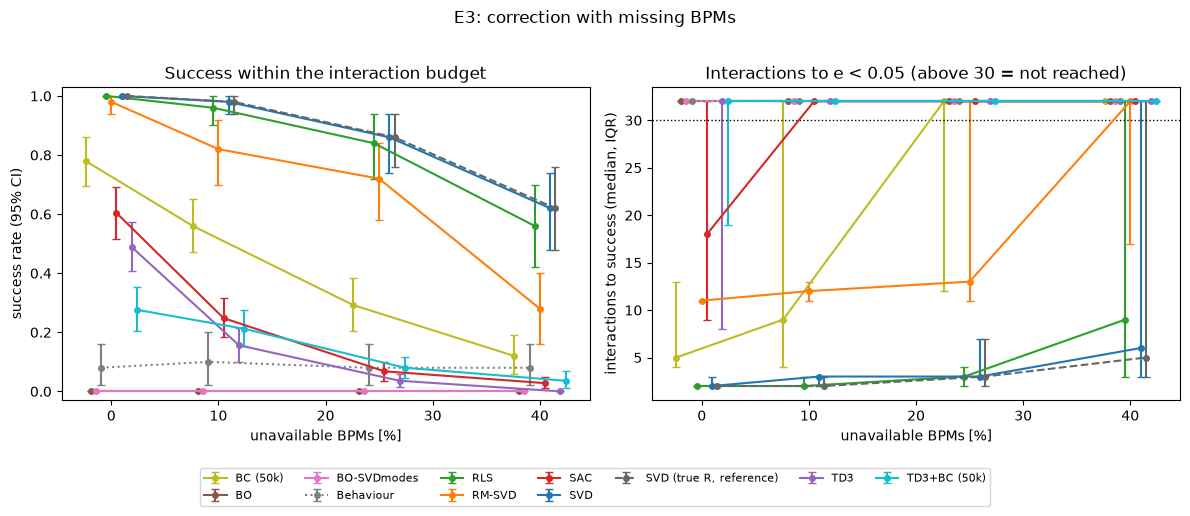

In [8]:
plotting.plot_sweep(
    results.e3,
    BUDGET,
    "masked_fraction",
    "unavailable BPMs [%]",
    "E3: correction with missing BPMs",
);

### E4: drift

Consecutive episodes on machines whose errors random-walk between episodes. RLS keeps its response estimate across episodes; SAC is either frozen or fine-tuned online on its own deployment data (no extra interactions).

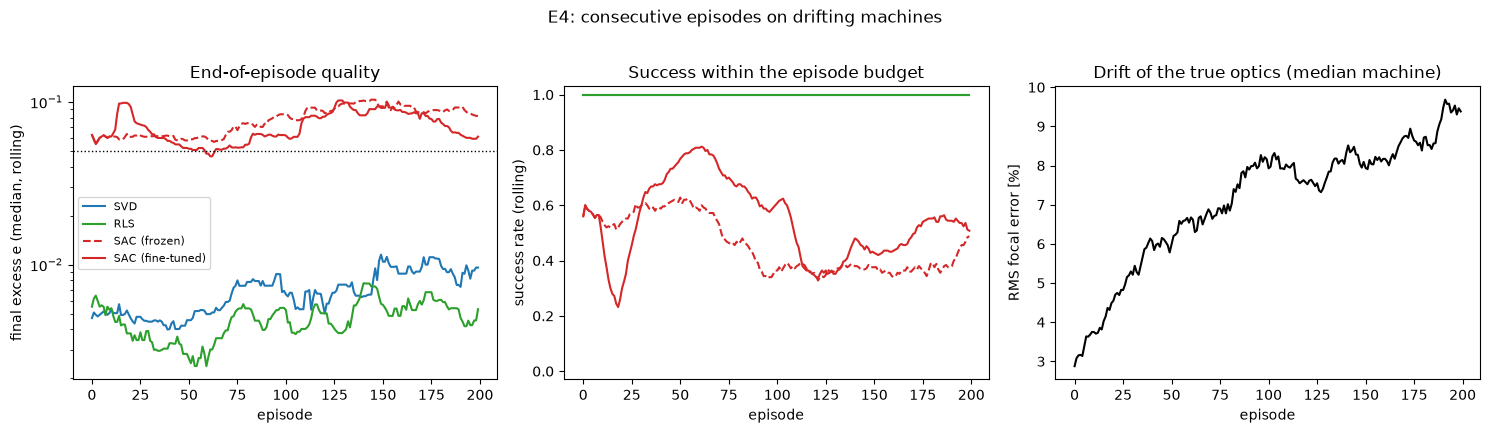

In [9]:
plotting.plot_drift(results.e4);

### E5: offline RL against its behaviour policy

The logging policy is SVD with the design model, a conservative gain and Gaussian exploration noise. Larger noise gives more diverse data but a worse behaviour policy.

| Method | Dataset | noise 5 urad | noise 20 urad | noise 50 urad |
|---|---|---|---|---|
| BC | 10k | 97% | 27% | 3% |
| Behaviour | (logging policy) | 90% | 8% | 0% |
| TD3+BC | 10k | 82% | 14% | 5% |
| BC | 50k | 100% | 83% | 17% |
| TD3+BC | 50k | 71% | 29% | 33% |

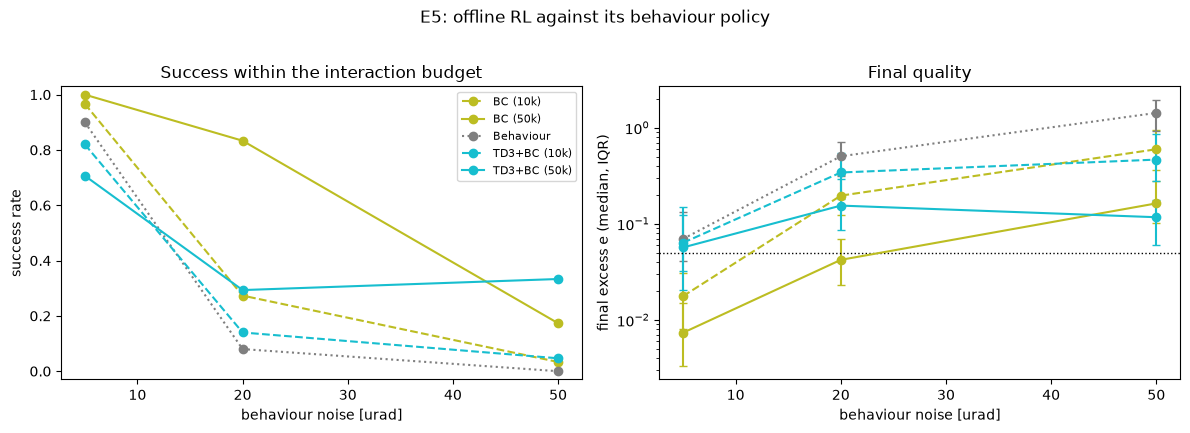

In [10]:
plotting.plot_offline_ablation(results.e5)
display(Markdown(report.offline_table(results)))

## 5. Findings, limitations and next steps

The summary and verdicts below are generated from the results; the generator refuses to print them if the results no longer support their wording.

In [11]:
display(Markdown("\n\n".join(report.findings(results))))
display(Markdown(report.hypotheses(results)))

With only the design optics model, iterative SVD correction reached the target (normalised excess RMS below 0.05) on 100% of held-out machines in a median of 2 interactions at nominal conditions, matching a privileged true-model reference, and it succeeded on every machine at every level of the specified 0-10% focal-error sweep; it only lost ground beyond that range (at 30%: 78% success, median 9 interactions), where adaptive RLS (94%) and response measurement (96%, but always 11 interactions) held up.

Online RL trained with domain randomisation (100,000 simulated steps per agent plus 600,000 for tuning) reached the target on only 60% (SAC) and 49% (TD3) of machines, Bayesian optimisation on 0% within 30 interactions, and offline learning from a noisy SVD log beat its behaviour policy (8%) mainly by imitation: behaviour cloning reached 78% with 50k transitions but 24% with 10k, and TD3+BC 28%.

Missing BPMs hurt every method most: with 40% unavailable, SVD succeeded on 62% of machines and no learned method on more than 12%; under 200 episodes of drift, RLS kept a median of 2 interactions while static SVD slowed from 3 to 4.

- **H1 (SVD with an exact model is near-optimal): supported.** With only the design model, SVD matched the privileged true-model reference at nominal conditions.
- **H2 (SVD degrades as model error grows): supported only beyond the specified range.** Iterative SVD with feedback gain kept succeeding throughout the 0-10% sweep, needing slightly more interactions as the error grew; it lost reliability only at 20-30% focal error.
- **H3 (adaptive response estimation recovers the loss): partly supported.** Within 0-10% there was no loss to recover. At 30% RLS and response measurement held up where SVD degraded, and under drift RLS kept needing fewer interactions than static SVD; response measurement always paid its fixed measurement cost.
- **H4 (simulation-trained RL is competitive in deployment interactions): not supported.** SAC and TD3 were less reliable than SVD at every model-error and missing-BPM level tested, on top of a large simulation-training cost; online fine-tuning on deployment data improved SAC under drift but left it far below SVD.
- **H5 (offline RL improves on its behaviour policy only with adequate data): supported, with a caveat.** Every offline agent beat the noisy logging policy, the larger dataset helped markedly, but plain behaviour cloning beat TD3+BC: the gain came from imitating (and denoising) the behaviour policy, not from RL.

**Limitations.** Linear thin-lens optics in the horizontal plane only, with no dispersion or coupling; synthetic, independent Gaussian errors on a single lattice; no real CERN data. RL training cost is simulation-only, and sim-to-real transfer is represented only by domain randomisation. Tuning budgets are small and identical for every method, so no method is shown at its best possible tuning, and RL results vary with which tuning configurations are drawn.

**Design decisions to keep in mind.** The RL agents choose their own action scale (a tuned hyperparameter) because the full hardware step range made SAC and TD3 fail outright; RLS uses a bounded covariance after its first version diverged under drift; the model-error sweep is extended beyond the specified range; and the normalised excess becomes easier to satisfy at very large model errors, which flatters weak methods there.

**Next steps.**
- Residual RL: learn a correction on top of SVD instead of replacing it, so the policy only has to fix the model error.
- Better excitation design for adaptive methods (persistent excitation within a fixed interaction budget) so that response estimation actually identifies the machine.
- Handle missing BPMs explicitly (for example, reconstructing unobserved readings from the model), since it is the non-ideality that hurt every method most.
- Validate against a real lattice model (MAD-X) and, eventually, machine data.